# Hello world: the shipped book in one call

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leon1706-lol/Aether-quant/blob/main/notebooks/00_hello_world.ipynb)

This is `aq hello` as a library call. It runs the project's shipped book on daily bars for 11 coins, through a cost-aware backtest, and prints the report: benchmarks, overfitting checks, and an honest note. No key, no Docker, no Lean.

The rule is long a coin while its trailing return over 20, 60 and 120 sessions is positive, with one vote per lookback. Weights are vol-scaled and capped, rebalanced every 5 sessions, and charged Coinbase's taker fee plus slippage.

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: install the library (numpy and pandas come with it)
    get_ipython().run_line_magic("pip", 'install -q "aether-quant[notebooks]"')  # noqa: F821
else:  # a clone: run against the checkout's code
    for parent in (Path.cwd(), *Path.cwd().parents):
        if (parent / "aether_quant" / "__init__.py").is_file():
            sys.path.insert(0, str(parent))
            break

## Run it

`offline=True` uses the sample that ships in the wheel (2021-06 to 2026-10), so this notebook gives the same numbers everywhere. Use `offline=False` to download fresh bars from Coinbase's public candles. A failed download falls back to the sample.

In [2]:
from aether_quant import hello

report = hello.run(offline=True)
print(hello.render_text(report))

Aether Quant: hello world
Rule     t3_crypto_trend_blend_x_eos (trend votes over 20/60/120 sessions, rebalanced every 5)
Data     11 coins, 2022-01-01 to 2026-10-31, bundled sample (Coinbase public candles, 2021-06-01 to 2026-10-31)
Costs    Coinbase taker fee 80 bps + 10 bps slippage per trade, 0.2% deadband

                    Shipped rule  BTC buy & hold  Equal weight
CAGR                        2.8%           10.4%          5.9%
Volatility                  7.2%           51.1%         67.1%
Sharpe (no T-bill)          0.43            0.50          0.49
Sortino                     0.66            0.72          0.70
Max drawdown               10.8%           67.6%         67.3%
Calmar                      0.26            0.15          0.09
Avg gross exposure         10.9%          101.0%        100.1%
Turnover / yr               2.7x            0.2x          1.6x
Costs / yr               243 bps          19 bps       140 bps

Overfitting checks
------------------
Probabilistic Sharp

## The equity curve against BTC

The shipped sleeve holds about 11% gross on average, so it is a small, low-volatility slice next to buying BTC outright. Compare Sharpe and drawdown, not total return.

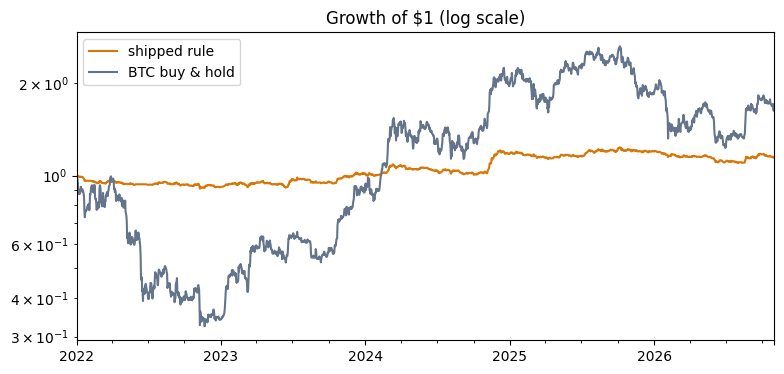

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

curves = pd.DataFrame({"shipped rule": report.equity, "BTC buy & hold": report.benchmark_equity})
curves.index = pd.to_datetime(curves.index)
axes = curves.plot(logy=True, figsize=(9, 4), color=["#d97706", "#64748b"], title="Growth of $1 (log scale)")
axes.set_xlabel("")
plt.show()

## The robustness grid

The same rule on 8 lookback variants. CSCV's PBO asks how often the variant that looked best in one half of the history did worse than the median variant in the other half. Above 0.5 means picking the best-looking variant is worse than picking one at random.

In [4]:
grid = pd.Series(report.grid_sharpes, name="Sharpe (no T-bill)")
grid.index = [f"a={a}, c={c}" for a in (10, 20, 30, 40) for c in (120, 180)]
print(f"PBO: {report.pbo:.2f}")
grid.to_frame()

PBO: 0.84


,Sharpe (no T-bill)
"a=10, c=120",0.354114
"a=10, c=180",0.498147
"a=20, c=120",0.431474
"a=20, c=180",0.573285
"a=30, c=120",0.521908
"a=30, c=180",0.601363
"a=40, c=120",0.386216
"a=40, c=180",0.540138


## Save it

`hello.save` writes a self-contained HTML page (no scripts, no external files) and/or the JSON report.

In [5]:
import tempfile

out = Path(tempfile.mkdtemp())
hello.save(report, html_path=out / "hello.html", json_path=out / "hello.json")
sorted(path.name for path in out.iterdir())

['hello.html', 'hello.json']

**Next:** [01 signal evaluation](01_signal_evaluation.ipynb) · [02 book construction](02_book_construction.ipynb) · [03 overfitting tests](03_overfitting_tests.ipynb)

*No verified edge: this is the project's shipped book, labelled improved, not verified.*